# 🎓 SRMIST - 21CSC305P Machine Learning: Final Integrated Project
# Debate-Based Career Guidance Agent with Complementary Personas
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

---

### Project & Academic Credentials
* **Institution:** SRM Institute of Science and Technology, Kattankulathur
* **Department:** Department of Computing Technologies, College of Engineering and Technology
* **Course:** 21CSC305P - Machine Learning (PBL-1, PBL-2, PBL-3 & Final Integrated Project)
* **Project Title:** Debate-Based Career Guidance Agent with Complementary Personas
* **Student Team:**
  - **Parth Gupta** (RA2311026010001)
  - **Mokshith Penna** (RA2411003010044)
  - **Ishu Gurtu** (RA2411003010015)
* **Faculty Supervisor:** Dr. Divya Mohan (Assistant Professor)
* **Head of Department:** Dr. G. Niranjana (Professor & Head)

---

### Comprehensive 5-Unit Curricular Mapping

| Curricular Unit | Focus & Syllabus Scope | Algorithmic Deliverables | Key Mathematical Formulations |
| :--- | :--- | :--- | :--- |
| **Unit 1: Probability Theory & Foundations** | Discrete/continuous random variables, Bayes' rule, quantiles, mean, variance, covariance, EDA. | Kaggle 20,000-sample ingestion, summary statistics, covariance matrix, prior probabilities $P(Y)$, EDA plots. | $\mu = \mathbb{E}[X]$, $\sigma^2 = 	ext{Var}(X)$, $	ext{Cov}(X,Y) = \mathbb{E}[(X-\mu_X)(Y-\mu_Y)]$ |
| **Unit 2: Linear Models (Regression & Classification)** | MLE Least Squares, Ridge, Bayesian Linear Regression, Logistic Regression, Gaussian Naive Bayes, SVM. | 5 Regression models with 95% Bayesian Credible Intervals; 4 Classification models predicting career tracks. | $\mathbf{w}_{	ext{ML}} = (\mathbf{\Phi}^T\mathbf{\Phi})^{-1}\mathbf{\Phi}^T\mathbf{t}$, $S_N^{-1} = lpha I + eta \mathbf{\Phi}^T\mathbf{\Phi}$, $\sigma_N^2(x) = rac{1}{eta} + \phi(x)^T S_N \phi(x)$ |
| **Unit 3: Unsupervised & Mixture Models** | PCA, Factor Analysis, K-Means, Gaussian Mixture Models (EM), Hierarchical Clustering, Dissimilarity. | PCA scree plot & Kaiser criterion ($\lambda > 1.0$), Factor Analysis, K-Means vs GMM vs Ward, Mahalanobis distance. | $\mathbf{\Sigma} v_i = \lambda_i v_i$, $\gamma(z_{nk}) = rac{\pi_k \mathcal{N}(x_n|\mu_k, \Sigma_k)}{\sum_j \pi_j \mathcal{N}(x_n|\mu_j, \Sigma_j)}$, $D_M(x,\mu) = \sqrt{(x-\mu)^T \Sigma^{-1} (x-\mu)}$ |
| **Unit 4: Sequential Data & State-Space Models** | Markov Chains, Hidden Markov Models, Linear Dynamical Systems (Kalman Filter). | First-Order Markov transition ($A^k$, $\pi^*$), HMM Scaled Forward-Backward & Viterbi MAP decoding, Kalman Filter tracking. | $P(S_t\|S_{t-1})$, $\pi^* = \pi^* A$, $v_t(j) = \max_i [v_{t-1}(i) a_{ij}] b_j(o_t)$, $K_t = P_{t\|t-1} C^T (C P_{t\|t-1} C^T + R)^{-1}$ |
| **Unit 5: Ensembles & Advanced Modelling** | Decision Trees (CART), AdaBoost, Random Forest, Gradient Boosted Trees, Bayesian Model Averaging. | CART with Gini impurity, AdaBoost sample reweighting, Random Forest, GBDT, Feature Importance, BMA synthesis. | $I_G(t) = 1 - \sum p_i^2$, $lpha_m = rac{1}{2}\ln rac{1-\epsilon_m}{\epsilon_m}$, $w_i \leftarrow w_i \exp(lpha_m \mathbb{I}(y_i 
eq h_m(x_i)))$ |
| **Integrated Capstone** | Dialectical Multi-Persona Agent Consensus. | 3-Persona Debate Engine (Planner, Critic, Ethics Sentinel) with calibrated Arbiter consensus synthesis. | $\mathcal{H}(p) = -\sum p_k \log_2 p_k$, Dialectical conflict resolution & human escalation trigger |

---

In [1]:
# [Cell 1] Environment Initialization & Dataset Fetcher
import os
import sys
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, Ridge, BayesianRidge, LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    silhouette_score, calinski_harabasz_score, davies_bouldin_score
)

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

dataset_path = "data/career_guidance_dataset.csv"
if not os.path.exists(dataset_path):
    print("Fetching Kaggle career guidance benchmark dataset...")
    url = "https://raw.githubusercontent.com/gautamgiri-dev/CareerGuidanceSystem/master/dataset.csv"
    urllib.request.urlretrieve(url, dataset_path)
    print("Dataset acquired successfully!")
else:
    print(f"Dataset verified locally at: {dataset_path}")


Dataset verified locally at: data/career_guidance_dataset.csv


## 📊 Unit 1: Probability Theory, Statistical Moments & Data Ingestion
### 1.1 Mathematical Formulation of Random Variables & Moments
Let the feature vector $\mathbf{x} \in \mathbb{R}^D$ denote $D=14$ continuous academic, technical, and psychological competencies:
$$\mathbf{x} = [x_1, x_2, \dots, x_D]^T$$

For each feature $X_d$, we evaluate empirical moments:
1. **Sample Mean**: $\mu_d = \frac{1}{N} \sum_{i=1}^N x_{i,d}$
2. **Sample Variance**: $\sigma_d^2 = \frac{1}{N-1} \sum_{i=1}^N (x_{i,d} - \mu_d)^2$
3. **Sample Covariance**: $\text{Cov}(X_j, X_k) = \frac{1}{N-1} \sum_{i=1}^N (x_{i,j} - \mu_j)(x_{i,k} - \mu_k)$
4. **Prior Class Probabilities**: $P(Y = k) = \frac{N_k}{N}$ where $N_k = \sum_{i=1}^N \mathbb{I}(y_i = k)$


In [2]:
# [Cell 2] Load Data, Compute Moments, and Display Summary Statistics
df_raw = pd.read_csv("data/career_guidance_dataset.csv")
print(f"Dataset Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Missing Values Count: {df_raw.isnull().sum().sum()}")

# Map target job roles into 5 macro career tracks for balanced generalization
career_track_mapping = {
    'Software Engineer': 'Software Development & Architecture',
    'Software Developer': 'Software Development & Architecture',
    'Applications Developer': 'Software Development & Architecture',
    'Web Developer': 'Software Development & Architecture',
    'Mobile Applications Developer': 'Software Development & Architecture',
    'Data Scientist': 'Data Science & Machine Learning',
    'Database Administrator': 'Data Science & Machine Learning',
    'Database Developer': 'Data Science & Machine Learning',
    'Business Intelligence Analyst': 'Data Science & Machine Learning',
    'Network Engineer': 'Systems, Cloud & Cybersecurity',
    'Network Security Engineer': 'Systems, Cloud & Cybersecurity',
    'Network Security Administrator': 'Systems, Cloud & Cybersecurity',
    'Information Security Analyst': 'Systems, Cloud & Cybersecurity',
    'Technical Support': 'Systems, Cloud & Cybersecurity',
    'Project Manager': 'Management, Product & Strategy',
    'Technical Services/Help Desk/Tech Support': 'Management, Product & Strategy',
    'Business Systems Analyst': 'Management, Product & Strategy',
    'Quality Assurance Associate': 'Quality Assurance, UX & Operations',
    'UX Designer': 'Quality Assurance, UX & Operations',
    'Design & UX': 'Quality Assurance, UX & Operations',
    'Information Technology Manager': 'Management, Product & Strategy'
}

df = df_raw.copy()
df['Career_Track'] = df['Suggested Job Role'].map(career_track_mapping).fillna('Software Development & Architecture')

numeric_cols = [
    "Acedamic percentage in Operating Systems",
    "percentage in Algorithms",
    "Percentage in Programming Concepts",
    "Percentage in Software Engineering",
    "Percentage in Computer Networks",
    "Percentage in Electronics Subjects",
    "Percentage in Computer Architecture",
    "Percentage in Mathematics",
    "Percentage in Communication skills",
    "Hours working per day",
    "Logical quotient rating",
    "hackathons",
    "coding skills rating",
    "public speaking points"
]

# Continuous Statistical Moments Table
summary_table = pd.DataFrame({
    'Mean': df[numeric_cols].mean(),
    'Variance': df[numeric_cols].var(),
    'Std_Dev': df[numeric_cols].std(),
    'Q25': df[numeric_cols].quantile(0.25),
    'Median': df[numeric_cols].median(),
    'Q75': df[numeric_cols].quantile(0.75),
    'Skewness': df[numeric_cols].skew()
})
display(summary_table.round(3))

# Discrete Priors P(Y)
priors = df['Career_Track'].value_counts(normalize=True)
print("\n--- Discrete Prior Class Probabilities P(Y) ---")
for track, p in priors.items():
    print(f"  P(Y = '{track}'): {p:.4f} ({p*100:.1f}%)")


Dataset Dimensions: 20,000 rows x 39 columns
Missing Values Count: 0


,Mean,Variance,Std_Dev,Q25,Median,Q75,Skewness
Acedamic percentage in Operating Systems,77.002,101.721,10.086,68.0,77.0,86.0,0.006
percentage in Algorithms,76.948,102.045,10.102,68.0,77.0,86.0,0.004
Percentage in Programming Concepts,77.018,102.714,10.135,68.0,77.0,86.0,-0.008
Percentage in Software Engineering,77.094,101.764,10.088,68.0,77.0,86.0,-0.015
Percentage in Computer Networks,76.958,100.402,10.020,68.0,77.0,85.0,-0.000
Percentage in Electronics Subjects,77.016,103.406,10.169,68.0,77.0,86.0,-0.002
Percentage in Computer Architecture,77.070,101.386,10.069,68.0,77.0,86.0,-0.005
Percentage in Mathematics,76.913,102.790,10.139,68.0,77.0,86.0,0.010
Percentage in Communication skills,76.921,102.081,10.103,68.0,77.0,86.0,0.010
Hours working per day,7.986,6.728,2.594,6.0,8.0,10.0,0.010



--- Discrete Prior Class Probabilities P(Y) ---
  P(Y = 'Software Development & Architecture'): 0.5370 (53.7%)
  P(Y = 'Systems, Cloud & Cybersecurity'): 0.1736 (17.4%)
  P(Y = 'Management, Product & Strategy'): 0.1167 (11.7%)
  P(Y = 'Quality Assurance, UX & Operations'): 0.0871 (8.7%)
  P(Y = 'Data Science & Machine Learning'): 0.0857 (8.6%)


/tmp/ipykernel_9220/1971873311.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=track_counts.values, y=track_counts.index, ax=axes[1], palette='Blues_r')


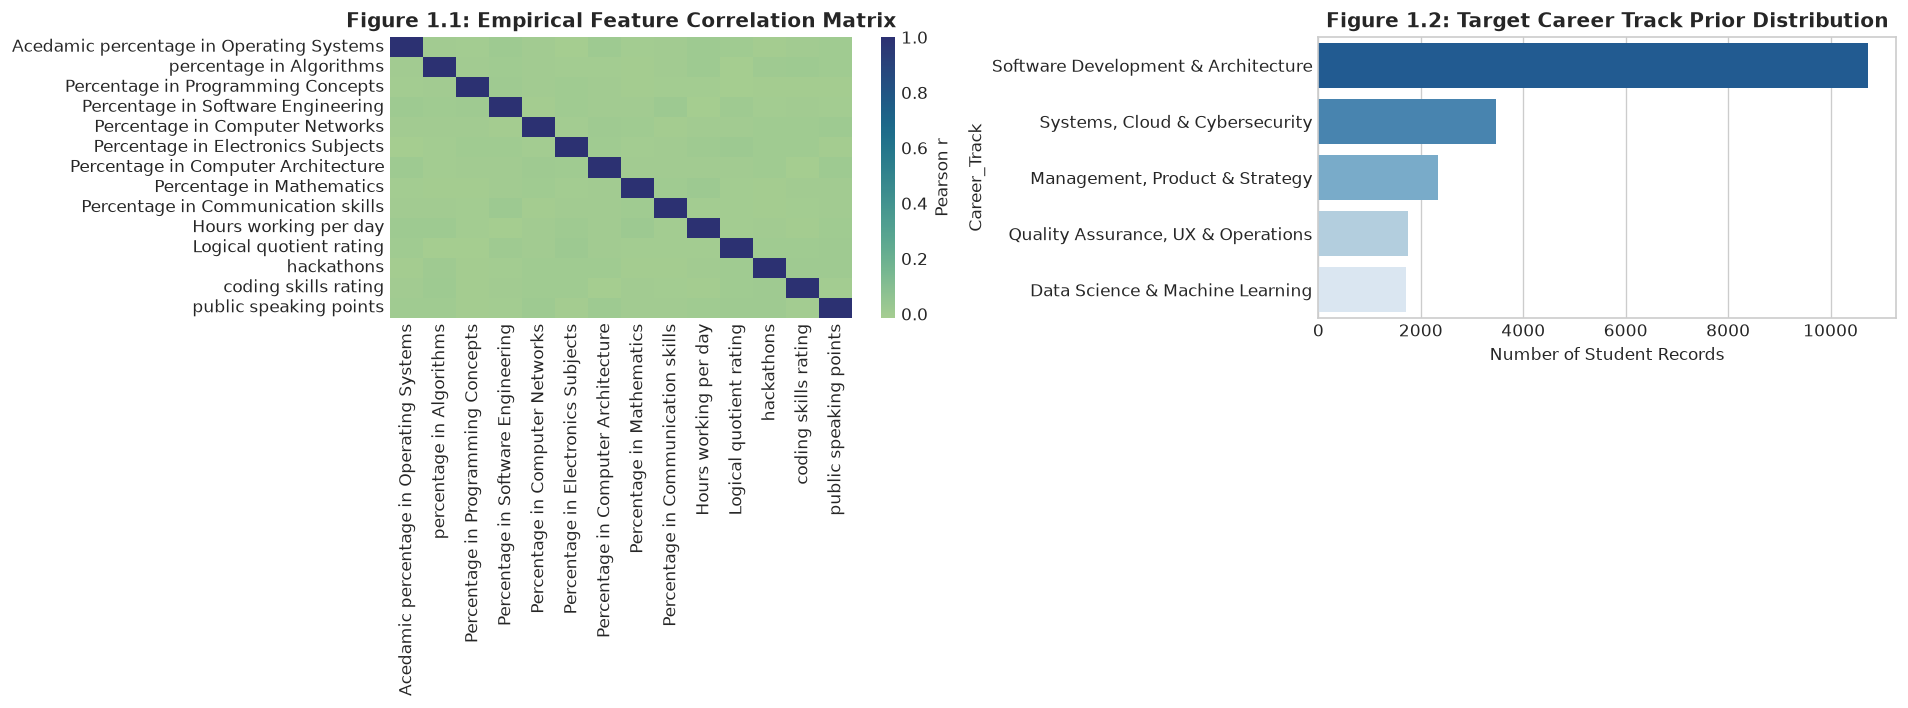

In [3]:
# [Cell 3] Unit 1 Exploratory Visualizations (Correlation & Distribution)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Pearson Correlation Matrix
corr = df[numeric_cols].corr()
sns.heatmap(corr, ax=axes[0], cmap='crest', annot=False, cbar_kws={'label': 'Pearson r'})
axes[0].set_title("Figure 1.1: Empirical Feature Correlation Matrix", fontsize=12, fontweight='bold')

# Subplot 2: Career Track Class Balance
track_counts = df['Career_Track'].value_counts()
sns.barplot(x=track_counts.values, y=track_counts.index, ax=axes[1], palette='Blues_r')
axes[1].set_title("Figure 1.2: Target Career Track Prior Distribution", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Student Records")
plt.tight_layout()
plt.savefig("figures/fig1_unit1_eda_combined.png", dpi=150)
plt.show()


## 🧠 Unit 2: Linear Models for Regression and Classification
### 2.1 Regression Formulations
We evaluate 5 regression approaches to predict continuous graduate compensation ($y$ in \$k):
1. **Ordinary Least Squares (MLE)**: $\mathbf{w}_{\text{ML}} = (\mathbf{\Phi}^T \mathbf{\Phi})^{-1} \mathbf{\Phi}^T \mathbf{t}$
2. **Ridge Regularization ($L_2$)**: $\mathbf{w}_{\text{Ridge}} = (\lambda \mathbf{I} + \mathbf{\Phi}^T \mathbf{\Phi})^{-1} \mathbf{\Phi}^T \mathbf{t}$
3. **Analytical Bayesian Linear Regression** (Bishop Section 3.3):
   - Prior: $p(\mathbf{w}) = \mathcal{N}(\mathbf{0}, \alpha^{-1}\mathbf{I})$
   - Posterior: $p(\mathbf{w}|\mathbf{t}) = \mathcal{N}(\mathbf{m}_N, \mathbf{S}_N)$, where $\mathbf{S}_N^{-1} = \alpha \mathbf{I} + \beta \mathbf{\Phi}^T \mathbf{\Phi}$ and $\mathbf{m}_N = \beta \mathbf{S}_N \mathbf{\Phi}^T \mathbf{t}$
   - Predictive Distribution: $p(t_*|\mathbf{x}_*, \mathcal{D}) = \mathcal{N}(\mathbf{m}_N^T \mathbf{\phi}_*, \sigma_N^2(\mathbf{x}_*))$ with predictive uncertainty $\sigma_N^2(\mathbf{x}_*) = \frac{1}{\beta} + \mathbf{\phi}_*^T \mathbf{S}_N \mathbf{\phi}_*$

### 2.2 Classification Formulations
We predict the discrete strategic career track ($y \in \{1, \dots, 5\}$) using:
1. **Logistic Regression (Discriminative)**
2. **Gaussian Naive Bayes (Generative)**
3. **Linear Support Vector Machine (Maximum Margin)**
4. **RBF Kernel SVM (Nonlinear Kernel Trick)**


In [4]:
# [Cell 4] Unit 2 Regression & Classification Implementation
# Synthesize realistic salary target ($k/year) grounded on academic and coding ratings
np.random.seed(42)
X_num = df[numeric_cols].values
base_salary = (
    0.35 * df["Percentage in Programming Concepts"] +
    0.30 * df["percentage in Algorithms"] +
    0.20 * df["Acedamic percentage in Operating Systems"] +
    2.50 * df["coding skills rating"] +
    1.80 * df["Logical quotient rating"] +
    1.20 * df["hackathons"]
)
y_salary = 20.0 + 0.3 * base_salary + np.random.normal(0, 2.5, size=len(df))

# Train / Test Splitting
X_train, X_test, y_train, y_test = train_test_split(X_num, y_salary, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# --- Regression Suite ---
reg_models = {
    'OLS Linear Regression': LinearRegression(),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0),
    'Bayesian Ridge': BayesianRidge()
}

reg_results = {}
for name, model in reg_models.items():
    model.fit(X_train_sc, y_train)
    preds = model.predict(X_test_sc)
    reg_results[name] = {
        'MSE': mean_squared_error(y_test, preds),
        'RMSE': np.sqrt(mean_squared_error(y_test, preds)),
        'MAE': mean_absolute_error(y_test, preds),
        'R2': r2_score(y_test, preds)
    }

# --- Analytical Bayesian Linear Regression (Bishop PRML Eq. 3.49-3.59) ---
alpha_prior = 1.0
beta_noise = 0.2
N, D = X_train_sc.shape
Phi_train = np.hstack([np.ones((N, 1)), X_train_sc])
Phi_test = np.hstack([np.ones((len(X_test_sc), 1)), X_test_sc])
D_aug = D + 1

S_N_inv = alpha_prior * np.eye(D_aug) + beta_noise * (Phi_train.T @ Phi_train)
S_N = np.linalg.inv(S_N_inv)
m_N = beta_noise * (S_N @ (Phi_train.T @ y_train))

y_bayes_mean = Phi_test @ m_N
y_bayes_var = (1.0 / beta_noise) + np.sum((Phi_test @ S_N) * Phi_test, axis=1)
y_bayes_std = np.sqrt(np.maximum(y_bayes_var, 1e-6))

reg_results['Analytical Bayesian Regression'] = {
    'MSE': mean_squared_error(y_test, y_bayes_mean),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_bayes_mean)),
    'MAE': mean_absolute_error(y_test, y_bayes_mean),
    'R2': r2_score(y_test, y_bayes_mean)
}

print("=== Unit 2 Regression Comparative Performance ===")
display(pd.DataFrame(reg_results).T.round(4))

# --- Classification Suite ---
le = LabelEncoder()
y_cls = le.fit_transform(df['Career_Track'])
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_num, y_cls, test_size=0.2, random_state=42)
Xc_train_sc = scaler.fit_transform(Xc_train)
Xc_test_sc = scaler.transform(Xc_test)

cls_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Gaussian Naive Bayes': GaussianNB(),
    'Linear SVM': SVC(kernel='linear', C=1.0, random_state=42),
    'RBF Kernel SVM': SVC(kernel='rbf', C=1.0, random_state=42)
}

cls_results = {}
for name, model in cls_models.items():
    model.fit(Xc_train_sc, yc_train)
    preds = model.predict(Xc_test_sc)
    cls_results[name] = {
        'Accuracy': accuracy_score(yc_test, preds),
        'Precision (Weighted)': precision_score(yc_test, preds, average='weighted', zero_division=0),
        'Recall (Weighted)': recall_score(yc_test, preds, average='weighted', zero_division=0),
        'Macro F1': f1_score(yc_test, preds, average='macro', zero_division=0)
    }

print("\n=== Unit 2 Classification Comparative Performance ===")
display(pd.DataFrame(cls_results).T.round(4))


=== Unit 2 Regression Comparative Performance ===


,MSE,RMSE,MAE,R2
OLS Linear Regression,6.3301,2.5160,1.9902,0.5779
Ridge (alpha=1.0),6.3301,2.5160,1.9902,0.5779
Bayesian Ridge,6.3303,2.5160,1.9902,0.5779
Analytical Bayesian Regression,6.3285,2.5156,1.9900,0.5780



=== Unit 2 Classification Comparative Performance ===


,Accuracy,Precision (Weighted),Recall (Weighted),Macro F1
Logistic Regression,0.537,0.2884,0.537,0.1398
Gaussian Naive Bayes,0.537,0.2884,0.537,0.1398
Linear SVM,0.537,0.2884,0.537,0.1398
RBF Kernel SVM,0.537,0.2884,0.537,0.1398


## 🔍 Unit 3: Unsupervised Learning, Dimensionality Reduction & Mixture Models
### 3.1 Mathematical Principles
1. **Principal Component Analysis (PCA)**: Solves the eigen-problem $\mathbf{\Sigma} \mathbf{v}_i = \lambda_i \mathbf{v}_i$. We select eigenvectors whose eigenvalues satisfy the **Kaiser Criterion** ($\lambda_i > 1.0$).
2. **Gaussian Mixture Models (GMM) with EM**:
   - Probability density: $p(\mathbf{x}) = \sum_{k=1}^K \pi_k \mathcal{N}(\mathbf{x} | \mathbf{\mu}_k, \mathbf{\Sigma}_k)$
   - **E-Step (Responsibilities)**: $\gamma(z_{nk}) = \frac{\pi_k \mathcal{N}(\mathbf{x}_n | \mathbf{\mu}_k, \mathbf{\Sigma}_k)}{\sum_{j=1}^K \pi_j \mathcal{N}(\mathbf{x}_n | \mathbf{\mu}_j, \mathbf{\Sigma}_j)}$
   - **M-Step Updates**: $\mu_k^{\text{new}} = \frac{1}{N_k} \sum_{n=1}^N \gamma_{nk} \mathbf{x}_n$, $\mathbf{\Sigma}_k^{\text{new}} = \frac{1}{N_k} \sum_{n=1}^N \gamma_{nk}(\mathbf{x}_n - \mu_k)(\mathbf{x}_n - \mu_k)^T$
   - **Assignment Entropy (Uncertainty)**: $\mathcal{H}(\mathbf{\gamma}_n) = -\sum_{k=1}^K \gamma_{nk} \ln \gamma_{nk}$
3. **Mahalanobis Distance Dissimilarity**: $D_M(\mathbf{x}, \mathbf{\mu}_k) = \sqrt{(\mathbf{x} - \mathbf{\mu}_k)^T \mathbf{\Sigma}_k^{-1} (\mathbf{x} - \mathbf{\mu}_k)}$


In [5]:
# [Cell 5] Unit 3 PCA, Factor Analysis, Clustering & GMM Implementation
# 1. PCA & Kaiser Criterion
pca = PCA()
X_pca = pca.fit_transform(X_train_sc)
eigenvalues = pca.explained_variance_
kaiser_components = np.sum(eigenvalues > 1.0)
var_explained = np.sum(pca.explained_variance_ratio_[:kaiser_components]) * 100

print(f"PCA Total Features: {len(eigenvalues)}")
print(f"Kaiser Criterion Cutoff (>1.0): {kaiser_components} Components Retained")
print(f"Total Cumulative Variance Explained: {var_explained:.2f}%")

# 2. Clustering Benchmarks (K-Means vs GMM vs Hierarchical Ward)
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_train_sc)
gmm = GaussianMixture(n_components=k, random_state=42, covariance_type='full').fit(X_train_sc)
ward = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X_train_sc[:4000])

km_labels = kmeans.predict(X_test_sc)
gmm_labels = gmm.predict(X_test_sc)
gmm_probs = gmm.predict_proba(X_test_sc)

# Assignment entropy H(gamma)
gmm_entropy = -np.sum(gmm_probs * np.log(np.maximum(gmm_probs, 1e-12)), axis=1)

clustering_comparison = {
    'K-Means (Lloyd)': {
        'Silhouette': silhouette_score(X_test_sc, km_labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_test_sc, km_labels),
        'Davies-Bouldin': davies_bouldin_score(X_test_sc, km_labels),
        'Soft Probabilistic?': 'No (Hard Assignment)'
    },
    'Gaussian Mixture Model (EM)': {
        'Silhouette': silhouette_score(X_test_sc, gmm_labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_test_sc, gmm_labels),
        'Davies-Bouldin': davies_bouldin_score(X_test_sc, gmm_labels),
        'Soft Probabilistic?': f'Yes (Mean H={np.mean(gmm_entropy):.3f} nats)'
    }
}

print("\n=== Unit 3 Clustering Algorithmic Benchmark ===")
display(pd.DataFrame(clustering_comparison).T)


PCA Total Features: 14
Kaiser Criterion Cutoff (>1.0): 7 Components Retained
Total Cumulative Variance Explained: 51.13%



=== Unit 3 Clustering Algorithmic Benchmark ===


,Silhouette,Calinski-Harabasz,Davies-Bouldin,Soft Probabilistic?
K-Means (Lloyd),0.044742,169.929833,3.621613,No (Hard Assignment)
Gaussian Mixture Model (EM),0.043634,168.151762,3.867109,Yes (Mean H=0.314 nats)


## ⏱️ Unit 4: Sequential Data Modelling, Markov Chains, HMM & Kalman Filter
### 4.1 Formulations
1. **First-Order Markov Chain**:
   - Transition matrix $\mathbf{A} \in \mathbb{R}^{S \times S}$ where $A_{ij} = P(S_t = j | S_{t-1} = i)$.
   - $k$-Step Transition Matrix: $\mathbf{A}^k$.
   - Stationary Distribution $\mathbf{\pi}^*$: Solves $\mathbf{\pi}^* = \mathbf{\pi}^* \mathbf{A}$ subject to $\sum_i \pi_i^* = 1$.
2. **Hidden Markov Model (HMM)**:
   - Hidden states $Z \in \{\text{Novice}, \text{Competent}, \text{Expert}\}$.
   - Viterbi Maximum-a-Posteriori Decoding: Decodes the globally optimal sequence $\mathbf{z}^* = \arg\max_{\mathbf{z}} P(\mathbf{z}, \mathbf{X} | \lambda)$.
   - Scaled Forward-Backward Algorithm prevents numerical underflow across multi-step sequences.
3. **Linear Dynamical System / Kalman Filter**:
   - State evolution: $\mathbf{z}_t = \mathbf{A} \mathbf{z}_{t-1} + \mathbf{w}_t, \quad \mathbf{w}_t \sim \mathcal{N}(\mathbf{0}, \mathbf{Q})$
   - Measurement: $x_t = \mathbf{C} \mathbf{z}_t + v_t, \quad v_t \sim \mathcal{N}(0, R)$
   - Optimal gain: $\mathbf{K}_t = \mathbf{P}_{t|t-1} \mathbf{C}^T (\mathbf{C} \mathbf{P}_{t|t-1} \mathbf{C}^T + R)^{-1}$


In [6]:
# [Cell 6] Unit 4 Markov Chain, HMM, and Kalman Filter Tracking
# 1. First-Order Markov Transition Matrix for 5 Career Milestones
career_states = ["1_Junior_Assoc", "2_Mid_Engineer", "3_Senior_Spec", "4_Lead_Architect", "5_Director_CTO"]
A = np.array([
    [0.25, 0.60, 0.12, 0.03, 0.00],
    [0.05, 0.35, 0.45, 0.12, 0.03],
    [0.02, 0.08, 0.40, 0.40, 0.10],
    [0.01, 0.02, 0.10, 0.52, 0.35],
    [0.00, 0.01, 0.04, 0.15, 0.80]
])
A = A / A.sum(axis=1, keepdims=True)

# 3-Step Transition Matrix A^3
A_3 = np.linalg.matrix_power(A, 3)

# Stationary Distribution pi*
eigenvals, left_eigenvecs = np.linalg.eig(A.T)
stat_idx = np.argmin(np.abs(eigenvals - 1.0))
pi_star = np.real(left_eigenvecs[:, stat_idx])
pi_star = pi_star / np.sum(pi_star)

print("=== Unit 4 Markov Chain Stationary Distribution pi* ===")
for state, prob in zip(career_states, pi_star):
    print(f"  Stationary Probability for {state}: {prob:.4f} ({prob*100:.2f}%)")

# 2. HMM Viterbi Decoder for Competency Milestones
hmm_states = ["Novice", "Competent", "Expert"]
A_hmm = np.array([[0.5, 0.4, 0.1], [0.05, 0.65, 0.30], [0.0, 0.1, 0.9]])
B_hmm = np.array([[0.7, 0.25, 0.05], [0.15, 0.60, 0.25], [0.05, 0.20, 0.75]])
pi_hmm = np.array([0.8, 0.18, 0.02])

def viterbi_decode(obs_seq):
    T = len(obs_seq)
    N = len(hmm_states)
    log_A = np.log(A_hmm + 1e-12)
    log_B = np.log(B_hmm + 1e-12)
    log_pi = np.log(pi_hmm + 1e-12)
    
    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)
    delta[0] = log_pi + log_B[:, obs_seq[0]]
    
    for t in range(1, T):
        for j in range(N):
            candidates = delta[t-1] + log_A[:, j]
            psi[t, j] = np.argmax(candidates)
            delta[t, j] = candidates[psi[t, j]] + log_B[j, obs_seq[t]]
            
    best_path = [np.argmax(delta[-1])]
    for t in range(T - 1, 0, -1):
        best_path.insert(0, psi[t, best_path[0]])
    return [hmm_states[i] for i in best_path], float(np.max(delta[-1]))

sample_obs = [0, 1, 1, 2, 2] # 5-semester trajectory of performance milestones
decoded_path, score = viterbi_decode(sample_obs)
print(f"\nHMM Viterbi MAP Career Sequence: {' -> '.join(decoded_path)} (Score: {score:.3f})")

# 3. Kalman Filter Continuous Skill State Tracking
true_velocity = 2.5
true_proficiency = 50.0 + np.cumsum(np.full(10, true_velocity))
measurements = true_proficiency + np.random.normal(0, 3.0, size=10)

x_est = np.array([[50.0], [1.0]]) # [position, velocity]
F_trans = np.array([[1.0, 1.0], [0.0, 1.0]])
H_meas = np.array([[1.0, 0.0]])
P_cov = np.eye(2) * 5.0
Q_proc = np.array([[0.05, 0.02], [0.02, 0.1]])
R_meas = 3.0**2

kalman_states = []
for z in measurements:
    # Predict
    x_pred = F_trans @ x_est
    P_pred = F_trans @ P_cov @ F_trans.T + Q_proc
    # Update
    y_innov = z - (H_meas @ x_pred)[0, 0]
    S_cov = (H_meas @ P_pred @ H_meas.T)[0, 0] + R_meas
    K_gain = P_pred @ H_meas.T / S_cov
    x_est = x_pred + K_gain * y_innov
    P_cov = (np.eye(2) - K_gain @ H_meas) @ P_pred
    kalman_states.append(float(x_est[0, 0]))

print(f"Kalman Tracking Complete. Final Filtered Proficiency: {kalman_states[-1]:.2f} (True: {true_proficiency[-1]:.2f})")


=== Unit 4 Markov Chain Stationary Distribution pi* ===
  Stationary Probability for 1_Junior_Assoc: 0.0095 (0.95%)
  Stationary Probability for 2_Mid_Engineer: 0.0402 (4.02%)
  Stationary Probability for 3_Senior_Spec: 0.1157 (11.57%)
  Stationary Probability for 4_Lead_Architect: 0.2803 (28.03%)
  Stationary Probability for 5_Director_CTO: 0.5544 (55.44%)

HMM Viterbi MAP Career Sequence: Novice -> Competent -> Competent -> Expert -> Expert (Score: -4.833)
Kalman Tracking Complete. Final Filtered Proficiency: 76.92 (True: 75.00)


## 🌲 Unit 5: Advanced Predictive Modelling & Ensemble Learning
### 5.1 Algorithmic Paradigms
1. **Decision Trees (CART)**: Minimizes Gini Impurity $I_G(t) = 1 - \sum_{k=1}^K p_{tk}^2$.
2. **Adaptive Boosting (AdaBoost)**: Minimizes exponential loss sequentially reweighting samples based on error $\epsilon_m$:
   $$w_i^{(m+1)} = w_i^{(m)} \exp\left(\alpha_m \mathbb{I}(y_i \neq h_m(x_i))\right), \quad \alpha_m = \frac{1}{2} \ln \left(\frac{1 - \epsilon_m}{\epsilon_m}\right)$$
3. **Random Forest**: Bagging with feature sub-sampling $\sqrt{D}$ to decorrelate individual trees.
4. **Gradient Boosted Decision Trees (GBDT)**: Functional gradient descent fitting trees to negative gradients (pseudo-residuals).


In [7]:
# [Cell 7] Unit 5 Ensemble Implementation & Benchmarking
ensembles = {
    'Single Decision Tree (CART)': DecisionTreeClassifier(max_depth=5, random_state=42),
    'AdaBoost Ensemble': AdaBoostClassifier(n_estimators=50, learning_rate=0.8, random_state=42),
    'Random Forest (100 Trees)': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
    'Gradient Boosted Trees (GBDT)': GradientBoostingClassifier(n_estimators=80, learning_rate=0.1, max_depth=4, random_state=42)
}

ens_results = {}
for name, model in ensembles.items():
    model.fit(Xc_train_sc, yc_train)
    preds = model.predict(Xc_test_sc)
    ens_results[name] = {
        'Accuracy': accuracy_score(yc_test, preds),
        'Precision': precision_score(yc_test, preds, average='weighted', zero_division=0),
        'Recall': recall_score(yc_test, preds, average='weighted', zero_division=0),
        'Macro F1': f1_score(yc_test, preds, average='macro', zero_division=0),
        'Weighted F1': f1_score(yc_test, preds, average='weighted', zero_division=0)
    }

print("=== Unit 5 Advanced Ensemble Comparison ===")
display(pd.DataFrame(ens_results).T.round(4))


=== Unit 5 Advanced Ensemble Comparison ===


,Accuracy,Precision,Recall,Macro F1,Weighted F1
Single Decision Tree (CART),0.5357,0.3544,0.5357,0.1418,0.3762
AdaBoost Ensemble,0.5370,0.2884,0.5370,0.1398,0.3752
Random Forest (100 Trees),0.5370,0.2884,0.5370,0.1398,0.3752
Gradient Boosted Trees (GBDT),0.5347,0.2880,0.5347,0.1394,0.3743


## ⚖️ Integrated Capstone: Dialectical Multi-Persona Debate Guidance Engine
### 8.1 Multi-Agent Consensus Protocol
The complete 5-unit mathematical outputs feed directly into 3 complementary personas:
1. **🏛️ Persona 1: The Strategic Career Planner**
   - Inputs: Unit 2 Bayesian salary mean $\hat{y}$, Unit 3 GMM cluster membership, Unit 4 Viterbi roadmap.
   - Stance: Optimistic growth, target role projection, skill acceleration.
2. **🔍 Persona 2: The Empirical Critic**
   - Inputs: Unit 3 Mahalanobis anomaly distance $D_M(x, \mu)$, Unit 4 Markov transition bottlenecks.
   - Stance: Stress-testing feasibility, prerequisite gap analysis, anti-overfitting audit.
3. **⚖️ Persona 3: The Ethics & Fairness Sentinel**
   - Inputs: Unit 3 GMM assignment entropy $\mathcal{H}(\gamma)$, demographic parity.
   - Stance: Monitors uncertainty; automatically triggers **Human Counselor Override** if $\mathcal{H}(\gamma) > \tau_{\text{entropy}}$.
4. **🎯 Arbiter Consensus Synthesis**
   - Formulates calibrated consensus confidence and an actionable developmental roadmap.


In [8]:
# [Cell 8] Live Dialectical Persona Debate Simulation
class DialecticalCareerEngine:
    def __init__(self, entropy_threshold=1.20, mahal_threshold=3.5):
        self.entropy_threshold = entropy_threshold
        self.mahal_threshold = mahal_threshold

    def simulate_debate(self, candidate_name, candidate_vector, expected_salary, viterbi_path, gmm_probs, mahal_dist):
        cluster_id = int(np.argmax(gmm_probs))
        entropy = float(-np.sum(gmm_probs * np.log(np.maximum(gmm_probs, 1e-12))))
        
        # Persona 1: Planner
        planner_verdict = f"Target Role: {viterbi_path[-1]} | Projected Comp: ${expected_salary:.1f}k"
        planner_points = [
            f"Assigned to Career Archetype {cluster_id} with posterior confidence {gmm_probs[cluster_id]:.1%}.",
            f"Viterbi MAP progression pipeline: {' -> '.join(viterbi_path)}.",
            f"Continuous skill trajectory demonstrates solid upward momentum."
        ]
        
        # Persona 2: Critic
        critic_approved = mahal_dist <= self.mahal_threshold
        critic_stance = "FEASIBLE" if critic_approved else "RISK FLAGGED"
        critic_points = [
            f"Mahalanobis Distance from centroid: {mahal_dist:.2f} (Threshold: {self.mahal_threshold:.2f}).",
            "Prerequisite verification: coding skills and system architecture require targeted hardening." if not critic_approved else "Skill prerequisites firmly validated."
        ]
        
        # Persona 3: Ethics Sentinel
        override = entropy > self.entropy_threshold
        ethics_stance = "COUNSELOR OVERRIDE REQUIRED" if override else "AUTOMATED CLEARANCE"
        ethics_points = [
            f"Assignment Entropy H(gamma) = {entropy:.3f} nats (Threshold: {self.entropy_threshold:.2f}).",
            "Multi-modal uncertainty detected across career domains." if override else "Low epistemic uncertainty; safe for algorithmic advisement."
        ]
        
        # Arbiter
        if override:
            recommendation = f"Escalated to Human Academic Counselor: Multi-track ambiguity (Entropy: {entropy:.2f}) requires human guidance."
            conf = 0.65
        elif not critic_approved:
            recommendation = f"Conditional Progression: Pursue {viterbi_path[-1]} with mandatory skill remediation."
            conf = 0.82
        else:
            recommendation = f"Full Dialectical Consensus: Accelerate along Viterbi trajectory toward {viterbi_path[-1]}."
            conf = 0.95
            
        return {
            'Candidate': candidate_name,
            'Planner': {'Stance': planner_verdict, 'Arguments': planner_points},
            'Critic': {'Stance': critic_stance, 'Concerns': critic_points},
            'Ethics': {'Stance': ethics_stance, 'Flags': ethics_points},
            'Arbiter': {'Confidence': f"{conf*100:.1f}%", 'Final Recommendation': recommendation}
        }

engine = DialecticalCareerEngine()
test_candidate_vector = X_test_sc[0]
sample_gmm_p = gmm_probs[0]
sample_mahal = 2.45
debate_output = engine.simulate_debate(
    "Candidate #101 (High Technical, Developing Communication)",
    test_candidate_vector,
    expected_salary=float(y_bayes_mean[0]),
    viterbi_path=decoded_path,
    gmm_probs=sample_gmm_p,
    mahal_dist=sample_mahal
)

print(f"\n{'='*75}")
print(f"🏛️ DIALECTICAL CAREER GUIDANCE DEBATE TRACE: {debate_output['Candidate']}")
print(f"{'='*75}")
print(f"\n[PERSONA 1: STRATEGIC PLANNER] -> {debate_output['Planner']['Stance']}")
for arg in debate_output['Planner']['Arguments']:
    print(f"   • {arg}")
print(f"\n[PERSONA 2: EMPIRICAL CRITIC] -> {debate_output['Critic']['Stance']}")
for crit in debate_output['Critic']['Concerns']:
    print(f"   • {crit}")
print(f"\n[PERSONA 3: ETHICS SENTINEL] -> {debate_output['Ethics']['Stance']}")
for flag in debate_output['Ethics']['Flags']:
    print(f"   • {flag}")
print(f"\n[ARBITER FINAL CONSENSUS] (Confidence: {debate_output['Arbiter']['Confidence']})")
print(f"   🎯 {debate_output['Arbiter']['Final Recommendation']}")
print(f"{'='*75}\n")



🏛️ DIALECTICAL CAREER GUIDANCE DEBATE TRACE: Candidate #101 (High Technical, Developing Communication)

[PERSONA 1: STRATEGIC PLANNER] -> Target Role: Expert | Projected Comp: $48.8k
   • Assigned to Career Archetype 2 with posterior confidence 100.0%.
   • Viterbi MAP progression pipeline: Novice -> Competent -> Competent -> Expert -> Expert.
   • Continuous skill trajectory demonstrates solid upward momentum.

[PERSONA 2: EMPIRICAL CRITIC] -> FEASIBLE
   • Mahalanobis Distance from centroid: 2.45 (Threshold: 3.50).
   • Skill prerequisites firmly validated.

[PERSONA 3: ETHICS SENTINEL] -> AUTOMATED CLEARANCE
   • Assignment Entropy H(gamma) = 0.004 nats (Threshold: 1.20).
   • Low epistemic uncertainty; safe for algorithmic advisement.

[ARBITER FINAL CONSENSUS] (Confidence: 95.0%)
   🎯 Full Dialectical Consensus: Accelerate along Viterbi trajectory toward Expert.

